In [60]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Problem 1

In [61]:
X = np.array([1, 1.75, 2, 3, 3.25, 4])

def uniform_kde(X, grid, h):
    """f_hat_h(x) on `grid`, uniform kernel. Pure computation, no plotting."""
    X = np.asarray(X)
    n = len(X)
    I = np.abs(grid[:, None] - X[None, :]) < h
    return I.sum(axis=1) / (2 * n * h)

### a.

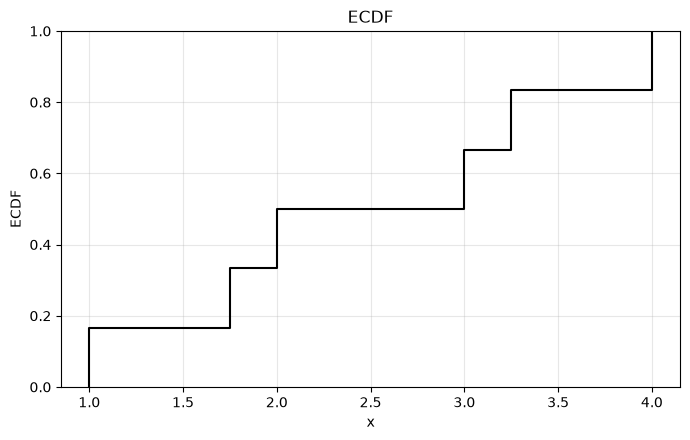

In [62]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.ecdfplot(x=X, color="black", ax=ax)
ax.set_xlabel("x")
ax.set_ylabel("ECDF")
ax.set_title("ECDF")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### b.

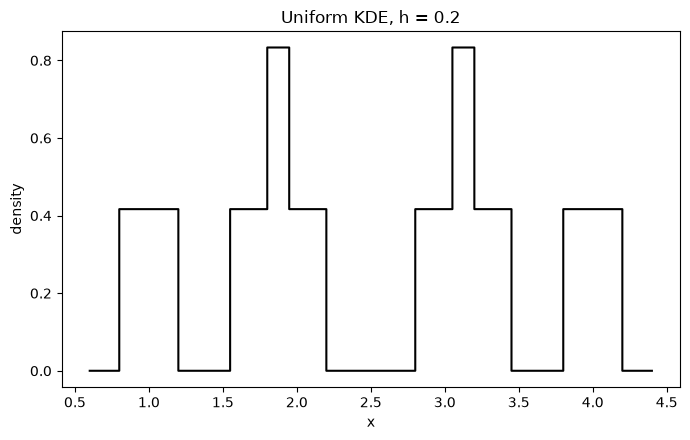

In [63]:
h = 0.2
g = np.linspace(X.min() - 2*h, X.max() + 2*h, 1000)
f = uniform_kde(X, g, h)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.step(g, f, where="mid", color="black")
ax.set_xlabel("x")
ax.set_ylabel("density")
ax.set_title("Uniform KDE, h = 0.2")
plt.tight_layout()
plt.show()

### c.

In [64]:
h_s = 1.84 * X.std() * len(X)**-0.2
print(f"Silverman h = {h_s:.4f}")

Silverman h = 1.2992


### d.

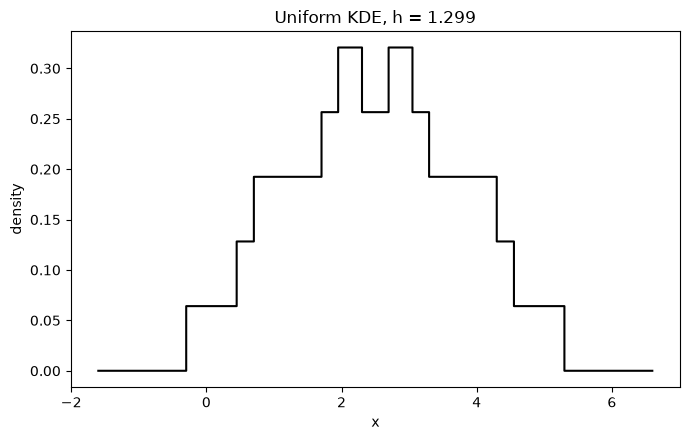

In [65]:
g = np.linspace(X.min() - 2*h_s, X.max() + 2*h_s, 1000)
f = uniform_kde(X, g, h_s)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.step(g, f, where="mid", color="black")
ax.set_xlabel("x")
ax.set_ylabel("density")
ax.set_title(f"Uniform KDE, h = {h_s:.3f}")
plt.tight_layout()
plt.show()

### e.

Both show step functions show the same general uniform shape. With $h = 0.2$, the windows barely overlap, so it has four narrow spikes with gaps of zero density between them. With the Silverman h, the windows are wide enough to the point that every one point overlaps others, so there are shorter and wider slopes with no gaps, like a mountain. It has higher bias and smooths the clusters into one hill.

# Problem 2

In [66]:
from math import erf, sqrt, pi

X = np.array([-1, -0.5, 0, 0.5, 1])

### a.

In [67]:
h = 0.6
fh0 = (np.abs(X) < h).sum() / (2 * len(X) * h)
print(fh0)

0.5


### b.

In [68]:
phi = lambda z: (1 + erf(z / sqrt(2))) / 2
Ef = (phi(h) - phi(-h)) / (2 * h)
print(Ef)

0.3762448037498774


### c.

In [69]:
f0 = 1 / sqrt(2 * pi)
print(f0)

0.3989422804014327


### d.

No. The estimator is around 0.023 below the true density. On average, the KDE underestimates the density at 0 because $E[f_h(0)]$ is an average of the true density over -0.6 to 0.6 instead of the single point 0. Everything else in this range is lower since 0 is the peak of the normal, and the average results in being lower than the peak.

### e.

In [70]:
h2 = 0.1
Ef2 = (phi(h2) - phi(-h2)) / (2 * h2)
print(Ef2)

0.3982783727702899


The difference is just 0.0007. The smaller h narrows the range being averaged over, so the average density approaches the actual density. Namely, as h approaches 0, $E[f_h(0)] \to f(0)$

### f.

Yes. A smaller range means less bias, and more data means the range still has enough points in it to be stable. Silverman's $h$ shrinks as $n$ grows, so both problems are resolved and the estimate approaches the true $f(x)$. It is biased for any fixed sample size but still consistent.

### g.

A small $h$ averages a narrow range, so the estimate has little bias but uses a small number of observations for each point, so the variance is higher and the curve would change on resampling. A large $h$ averages over a wider range, so the estimate is stable across resamples, but smooths peaks. We want an $h$ small enough to retain the overall structure but large enough so that each range has enough points

# Problem 3

In [71]:
X = np.array([5, 7, 7, 8, 10])
h = 1.5

### a.

In [72]:
xs = np.array([6, 6.5, 7, 8, 8.5])
fu = (np.abs(xs[:, None] - X[None, :]) < h).sum(1) / (2 * len(X) * h)
print(fu)

[0.2        0.13333333 0.2        0.2        0.06666667]


### b.

In [73]:
Z = (xs[:, None] - X[None, :]) / h
fg = (np.exp(-Z**2 / 2) / np.sqrt(2 * np.pi)).sum(1) / (len(X) * h)
print(fg)

[0.15116668 0.16865731 0.17804448 0.16744524 0.15060231]


### c.

The biggest jump in a. is from x= 8.0 to 8.5, where the estimate goes from 0.2 to 0.0667, since both observations at 7 leave the range and the number of points considered goes from 3 to 1. This happens since the uniform kernel is rectangular, and every observation is immediately removed from consideration as soon as it's out of the range, but the Gaussian kernel has no edges. Its curve decreases continuously with distance, and the two observations at 7 don't immediately drop when x goes to 8, but rather have less weight as x moves on.

### d.

We might prefer the Gaussian for showing a density estimate since it is a smooth curve, and real densities are smooth. The steps in the uniform kernel are limited in that have jumps we see in part a and are less accurate over a range.

We might prefer the uniform kernel when we are drawing by hand, since they are rectangular and point-based

# Problem 4

In [74]:
import pandas as pd

df = pd.read_csv("./data/heart_failure_clinical_records_dataset.csv")

### a.

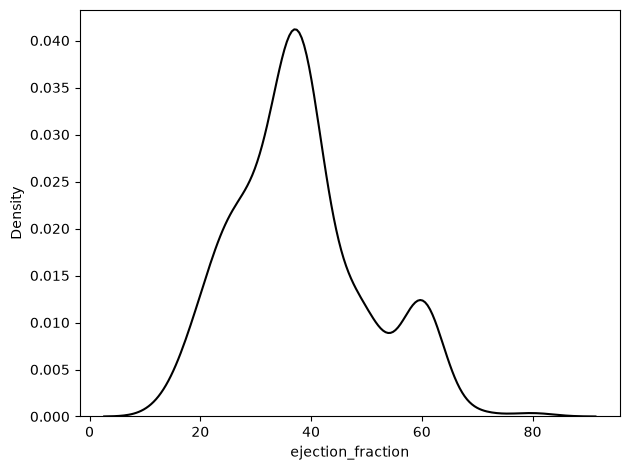

In [75]:
fig, ax = plt.subplots()
sns.kdeplot(data=df, x="ejection_fraction", color="black", ax=ax)
plt.tight_layout()
plt.show()

### b.

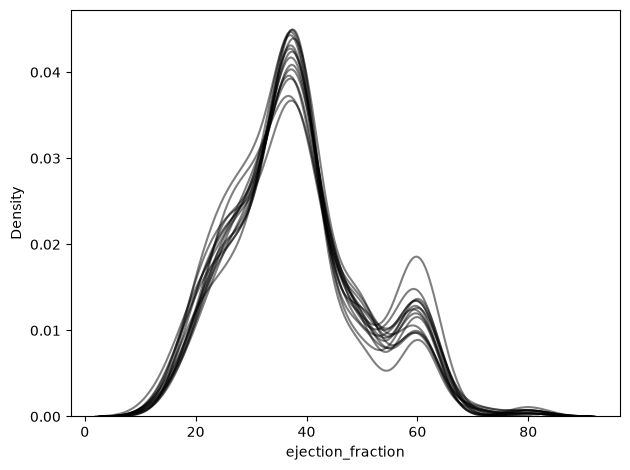

In [76]:
fig, ax = plt.subplots()
for _ in range(15):
    s = df.sample(frac=1.0, replace=True)
    sns.kdeplot(data=s, x="ejection_fraction", color="black", alpha=0.5, ax=ax)
plt.tight_layout()
plt.show()

### c.

The curves are tightest on the slopes up and down and the tails ($x < 25$, $x \approx 40 \text{ to } 50$, $x > 60$), so the estimate is reliable there. The curves generally have the same shape everywhere with the same general spread. The noticeable variation happens at the peaks ($x\approx 40$, and $x\approx 60$), where the spreads are the thickest.